In [1]:
import matplotlib.pyplot as plt
import torch
from datetime import datetime
import os
import sys
import numpy as np
sys.path.append("..")
from common.mlp_utils import FUSION_METHODS, best_metrics

ACCURACY_DIR = "test_result_mmlu_auxiliary_train_mmlu_test/accuracy"

replace_types = ["seq", "single", "smart_seq"]
fusions = list(FUSION_METHODS.keys())
fusions += ["zero"]
fusions += [f"Best_{metric}" for metric in best_metrics.keys()]

In [2]:
import sys
sys.path.append("..")
from common.seeding import set_seed
from config import SEED
set_seed(SEED)


In [3]:
colors = plt.cm.tab20(np.linspace(0, 1, len(fusions)))
def draw(data, save=False):
    nrows = len(replace_types)
    data_keys = list(data.keys())
    plt.figure(figsize=(2 * 10, nrows * 10))
    for i, replace in enumerate(replace_types):
        plt.subplot(nrows, 2, i * 2 + 1)

        to_break = True
        for name, xs in data.items():
            if replace in xs:
                to_break = False
                plt.plot(xs[replace] if replace != "single" else sorted(xs[replace], reverse=True), label=name.lower().replace('_', '-'))
        if to_break:
            continue
        
        plt.legend()
        plt.xlabel("Number of changed layer" + ("s" if replace == "seq" else ""))
        plt.ylabel("Accuracy")
        plt.title(f"Accuracy after changing {replace} layer (from best to worst)")

        plt.subplot(nrows, 2, i * 2 + 2)


        vp = plt.violinplot([data[key][replace] for key in data_keys if replace in data[key]])
        for i, body in enumerate(vp['bodies']):
            body.set_facecolor(colors[i])
        plt.legend(list(map(lambda name:name.lower().replace('_', '-'), data_keys)))
        # plt.ylim((0, 1.1))
        # plt.xlabel("Number of changed layer" + ("s" if replace == "seq" else ""))
        plt.ylabel("Accuracy")
        plt.title(f"Accuracy after changing {replace} layer")

    if save:
        os.makedirs(f"plots/accuracy", exist_ok=True)
        plt.savefig(f"plots/accuracy/accuracy_{datetime.now().strftime('%Y_%m_%d_%H_%M_%S')}.png")
    plt.show()
    plt.close()

In [4]:
loading = "\n".join([
    f"replace_with_{replace}_{fusion} = torch.load('{ACCURACY_DIR}/accuracy_list_{replace}_{fusion}.pt')"
    for fusion in fusions
    for replace in replace_types
    if os.path.exists(f"{ACCURACY_DIR}/accuracy_list_{replace}_{fusion}.pt")
])
exec(loading)

# Build the nested dictionary directly to avoid nested f-string quoting issues.
data = {}
for fusion in fusions:
    label = f"Replace with {fusion.replace('Projection', 'Pruning')}"
    items = {}
    for replace in replace_types:
        path = f"{ACCURACY_DIR}/accuracy_list_{replace}_{fusion}.pt"
        if os.path.exists(path):
            items[replace] = torch.load(path)
    if items:
        data[label] = items

for key1 in data.keys():
    for key2 in data[key1].keys():
        print(key1, key2, data[key1][key2])
        print()

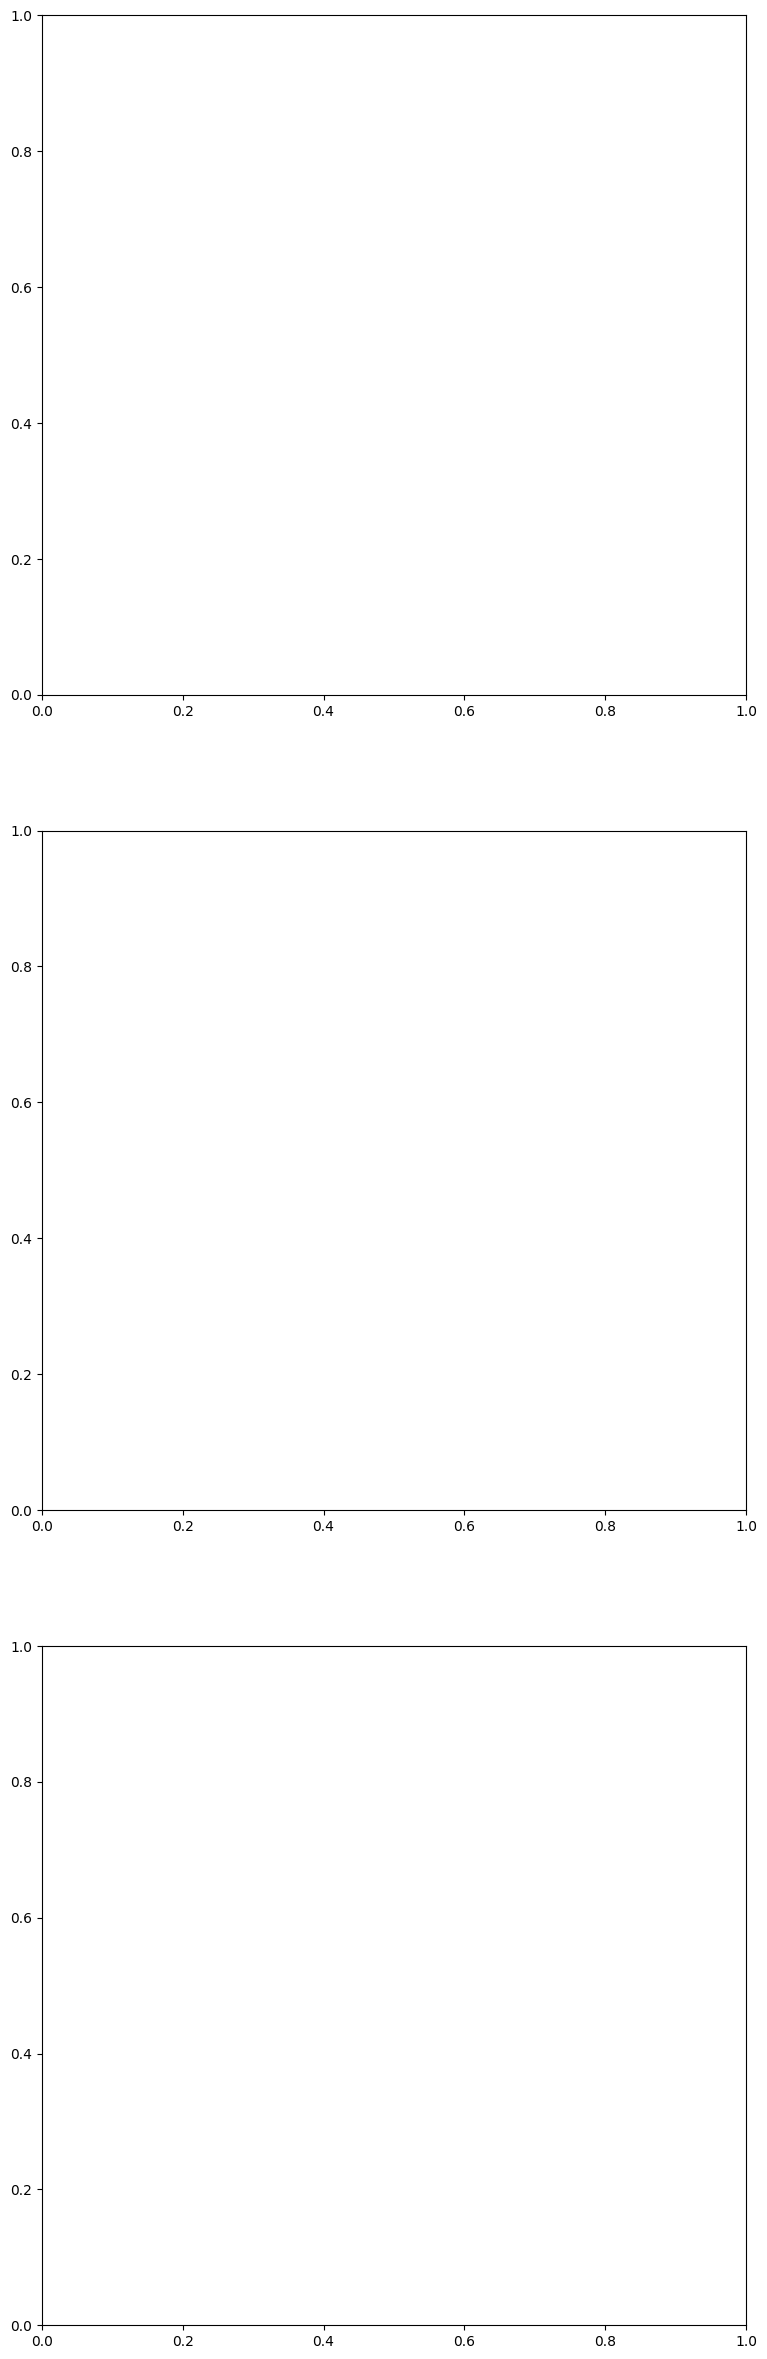

In [5]:
draw(data, save=True)

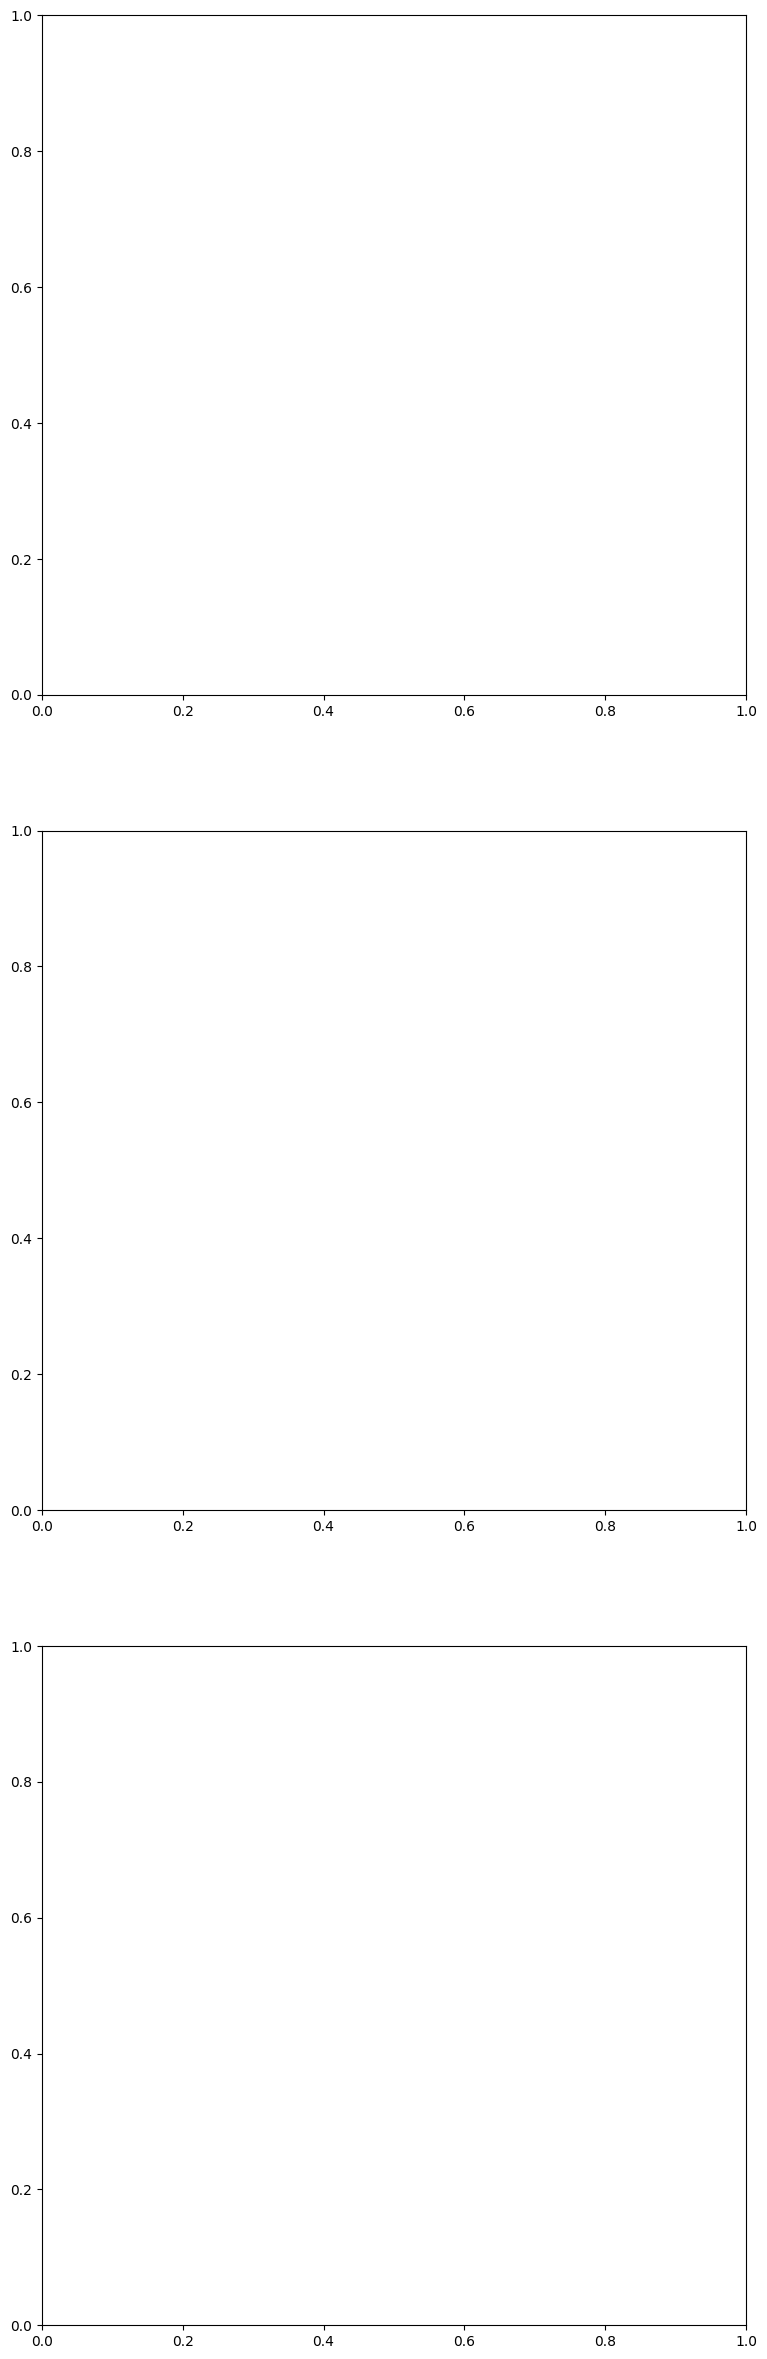

In [6]:
data = {
   # 'Replace with ZipIt': {'seq': replace_with_seq_ZipIt, 'single': replace_with_single_ZipIt},
   # 'Replace with Average': {'seq': replace_with_seq_Average, 'single': replace_with_single_Average},
   # 'Replace with Pruning': {'seq': replace_with_seq_Projection, 'single': replace_with_single_Projection},
   # 'Replace with Procrustes': {'seq': replace_with_seq_Procrustes, 'single': replace_with_single_Procrustes},
   # 'Replace with Fisher': {'seq': replace_with_seq_Fisher, 'single': replace_with_single_Fisher},
   # 'Replace with TIES': {'seq': replace_with_seq_TIES, 'single': replace_with_single_TIES},
   # 'Replace with Distillation': {'seq': replace_with_seq_Distillation, 'single': replace_with_single_Distillation},
   # 'Replace with FineTune_ZipIt': {'seq': replace_with_seq_FineTune_ZipIt, 'single': replace_with_single_FineTune_ZipIt},
   # 'Replace with FineTune_Average': {'seq': replace_with_seq_FineTune_Average, 'single': replace_with_single_FineTune_Average},
   # 'Replace with FineTune_Pruning': {'seq': replace_with_seq_FineTune_Projection, 'single': replace_with_single_FineTune_Projection},
   # 'Replace with FineTune_Procrustes': {'seq': replace_with_seq_FineTune_Procrustes, 'single': replace_with_single_FineTune_Procrustes},
   # 'Replace with FineTune_Fisher': {'seq': replace_with_seq_FineTune_Fisher, 'single': replace_with_single_FineTune_Fisher},
   # 'Replace with FineTune_TIES': {'seq': replace_with_seq_FineTune_TIES, 'single': replace_with_single_FineTune_TIES},
   # 'Replace with FineTune_Distillation': {'seq': replace_with_seq_FineTune_Distillation, 'single': replace_with_single_FineTune_Distillation},
   # 'Replace with zero': {'seq': replace_with_seq_zero, 'single': replace_with_single_zero},
   # 'Replace with Best_MSE': {'seq': replace_with_seq_Best_MSE, 'single': replace_with_single_Best_MSE},
   # 'Replace with Best_RMSE': {'seq': replace_with_seq_Best_RMSE, 'single': replace_with_single_Best_RMSE},
   # 'Replace with Best_MAE': {'seq': replace_with_seq_Best_MAE, 'single': replace_with_single_Best_MAE},
   # 'Replace with Best_RelMSE': {'seq': replace_with_seq_Best_RelMSE, 'single': replace_with_single_Best_RelMSE},
   # 'Replace with Best_Cosine': {'seq': replace_with_seq_Best_Cosine, 'single': replace_with_single_Best_Cosine},
   # 'Replace with Best_Pearson': {'seq': replace_with_seq_Best_Pearson, 'single': replace_with_single_Best_Pearson},
   # 'Replace with Best_R2': {'seq': replace_with_seq_Best_R2, 'single': replace_with_single_Best_R2},
   # 'Replace with Best_JS': {'seq': replace_with_seq_Best_JS, 'single': replace_with_single_Best_JS},
   # 'Replace with Best_KL': {'seq': replace_with_seq_Best_KL, 'single': replace_with_single_Best_KL},
   # 'Replace with Best_Top1': {'seq': replace_with_seq_Best_Top1, 'single': replace_with_single_Best_Top1},
   # 'Replace with Best_Top5': {'seq': replace_with_seq_Best_Top5, 'single': replace_with_single_Best_Top5},
   # 'Replace with Best_EntropyGap': {'seq': replace_with_seq_Best_EntropyGap, 'single': replace_with_single_Best_EntropyGap},
   # 'Replace with Best_CKA': {'seq': replace_with_seq_Best_CKA, 'single': replace_with_single_Best_CKA},
}

draw(data)

In [7]:
# exec(def_data)

In [8]:
import pandas as pd
from openpyxl import load_workbook
from openpyxl.formatting.rule import ColorScaleRule

tables_path = os.path.join(ACCURACY_DIR, 'accuracy_tables.xlsx')
with pd.ExcelWriter(tables_path, engine='openpyxl') as writer:
    for replace in replace_types:
        rows = {}
        for method, result in data.items():
            if replace not in result:
                continue

            values = list(result[replace])
            if replace == 'single':
                values = sorted(values, reverse=True)

            rows[method] = values

        if not rows:
            continue

        max_len = max(len(values) for values in rows.values())
        df = pd.DataFrame(
            {method: values + [np.nan] * (max_len - len(values)) for method, values in rows.items()},
            index=range(1, max_len + 1),
        ).T
        df.columns = list(range(1, max_len + 1))
        df.index.name = 'Method'
        df.to_excel(writer, sheet_name=replace)

workbook = load_workbook(tables_path)
for sheet_name in workbook.sheetnames:
    ws = workbook[sheet_name]
    if ws.max_row > 1 and ws.max_column > 1:
        ws.conditional_formatting.add(
            f'B2:{ws.cell(ws.max_row, ws.max_column).coordinate}',
            ColorScaleRule(
                start_type='min', start_color='FFFFFF',
                mid_type='percentile', mid_value=50, mid_color='FFF2CC',
                end_type='max', end_color='63BE7B',
            ),
        )

workbook.save(tables_path)
print(f'Tables saved to {tables_path}')

OSError: Cannot save file into a non-existent directory: 'test_result_mmlu_auxiliary_train_mmlu_test/accuracy'

In [ ]:
nrows = len(replace_types)
plt.figure(figsize=(2 * 10, nrows * 10))
data_keys = list(data.keys())
for ind, replace in enumerate(replace_types):
    zipped = list(zip(*[data[key][replace] for key in data_keys]))
    ordered = [[sum([zipped[i][k] < zipped[i][j] for k in range(len(zipped[0]))])
    for i in range(len(zipped))] for j in range(len(zipped[0]))]

    plt.axis(False)
    plt.subplot(nrows, 2, 2*ind + 1)
    plt.title(f"Rank for {replace} (higher is better)")
    for i, key in enumerate(data_keys):
        plt.plot(ordered[i], label = key)
    plt.legend()

    plt.subplot(nrows, 2, 2*ind + 2)
    plt.title(f"Rank for {replace} (higher is better)")
    vp = plt.violinplot(ordered)
    for i, body in enumerate(vp['bodies']):
        body.set_facecolor(colors[i])
    plt.legend(data_keys)

    for ind, key in enumerate(data_keys):
        print(f"{sum(ordered[ind]) / len(ordered[ind]):.2f} - Mean rank for {replace} {key}")
if True:
    os.makedirs(f"plots/accuracy", exist_ok=True)
    plt.savefig(f"plots/accuracy/rank_{datetime.now().strftime('%Y_%m_%d_%H_%M_%S')}.png")
plt.show()
plt.close()

IndexError: list index out of range

<Figure size 2000x3000 with 0 Axes>

In [ ]:
logs = torch.load(f"logs/fusion/{list(sorted(list(os.walk('logs/fusion'))[0][2]))[-1]}")
logs = [{k:v for k, v in log.items() if k[:4] != "Best"} for log in logs]

In [ ]:
len(logs)

736

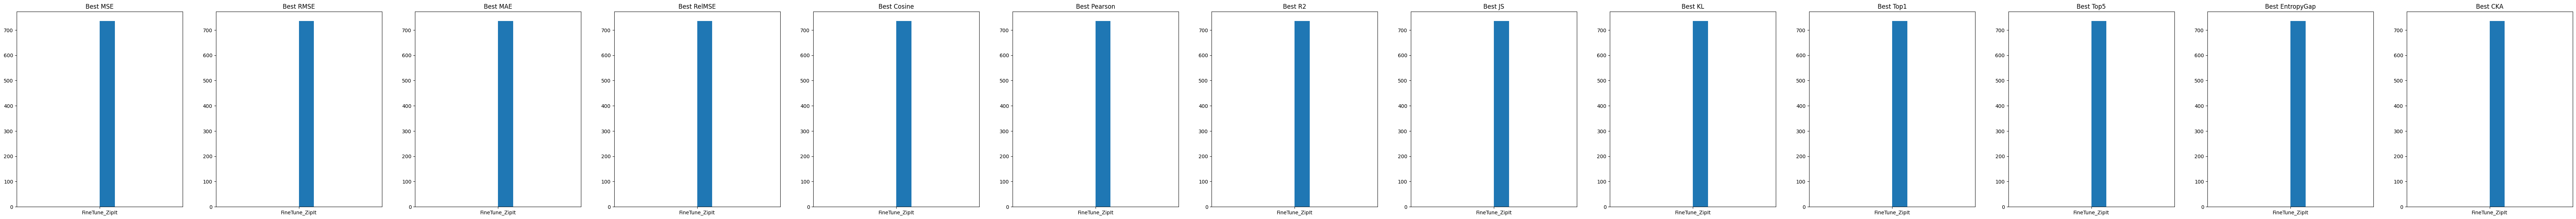

In [ ]:
plt.figure(figsize=(len(best_metrics) * 7, 7))
for ind, (metric, inverse) in enumerate(best_metrics.items()):
    plt.subplot(1, len(best_metrics), ind+1)
    def get_best(results):
        best_key = list(results.keys())[0]
        for key in results.keys():
            if (results[key][metric] < results[best_key][metric]) != inverse:
                best_key = key
        return best_key
    best = [get_best(fusion) for fusion in logs]
    plt.hist(best)
    plt.title(f"Best {metric}")
plt.show()

In [ ]:
plt.plot([- result["ZipIt"]["Cosine"] + result["FineTune_Projection"]["Cosine"] for result in logs])
plt.ylim(-1, 1)

KeyError: 'ZipIt'

In [ ]:
plt.plot(sorted([result["FineTune_Fisher"]["Cosine"] for result in logs]))
plt.plot(sorted([result["Projection"]["Cosine"] for result in logs]))
plt.ylim(-1, 1)

KeyError: 'FineTune_Fisher'

In [ ]:
lens = []
for ind in range(24):
    lens.extend(list(map(len, torch.load(f"data/activations/pairs_train_{ind}.pt"))))
lens = sorted(lens)

In [9]:
from pathlib import Path




def _latest_accuracy_dir(experiment_root):
    root = Path(experiment_root).expanduser().resolve()
    candidates = []

    direct = root / 'accuracy'
    if direct.is_dir():
        candidates.append(direct)

    candidates.extend(path for path in root.glob('*/accuracy') if path.is_dir())

    if not candidates:
        raise FileNotFoundError(f'No accuracy directories found under {root}')

    return max(candidates, key=lambda path: path.stat().st_mtime)


def _experiment_name(experiment_root):
    root = Path(experiment_root).expanduser().resolve()
    return root.name or str(root)


def load_many_data(experiment_roots):
    many_data = {}
    for experiment_root in experiment_roots:
        accuracy_dir = _latest_accuracy_dir(experiment_root)
        experiment_name = _experiment_name(experiment_root)
        result_name = accuracy_dir.parent.name
        label_prefix = f'{experiment_name} | {result_name}'

        experiment_data = {}
        for fusion in fusions:
            label = f"Replace with {fusion.replace('Projection', 'Pruning')}"
            items = {}
            for replace in replace_types:
                path = accuracy_dir / f'accuracy_list_{replace}_{fusion}.pt'
                if path.exists():
                    items[replace] = torch.load(path)
            if items:
                experiment_data[f'{label_prefix} | {label}'] = items

        if experiment_data:
            many_data[label_prefix] = experiment_data

    return many_data


def draw_many_data(many_data, save=False, figsize=(10, 20)):
    if not many_data:
        print('No experiment data found')
        return

    nrows = len(replace_types)
    plt.figure(figsize=figsize)

    for row, replace in enumerate(replace_types):
        ax = plt.subplot(nrows, 1, row + 1)
        plotted = False

        for _, experiment_data in many_data.items():
            for method_name, xs in experiment_data.items():
                if replace not in xs:
                    continue

                values = list(xs[replace])
                if replace == 'single':
                    values = sorted(values, reverse=True)

                ax.plot(
                    range(len(values)),
                    values,
                    linewidth=2,
                    alpha=0.85,
                    label=method_name,
                )
                plotted = True

        ax.grid(True, alpha=0.25)
        ax.set_ylim(0.0, 1.0)
        ax.set_ylabel('Accuracy')
        ax.set_title(f'Accuracy after changing {replace} layer')
        ax.set_xlabel('Number of changed layers')
        if plotted:
            ax.legend(fontsize=7)
        else:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes)

    plt.tight_layout()
    if save:
        out_dir = 'plots/multi_experiment'
        os.makedirs(out_dir, exist_ok=True)
        plt.savefig(os.path.join(out_dir, f"accuracy_{datetime.now().strftime('%Y_%m_%d_%H_%M_%S')}.png"))
    plt.show()
    plt.close()




In [10]:
EXPERIMENT_DIRS = [
    '/glazkov-dev/qwen_moe_fusion_PI',
    '/glazkov-dev/qwen_moe_fusion_EC',
    '/glazkov-dev/qwen_moe_fusion_PI_greedy',
    '/glazkov-dev/qwen_moe_fusion_EC_greedy',
    '/glazkov-dev/qwen_moe_exp_fusion_on_default_pairing',
]

In [11]:
many_data = load_many_data(EXPERIMENT_DIRS)


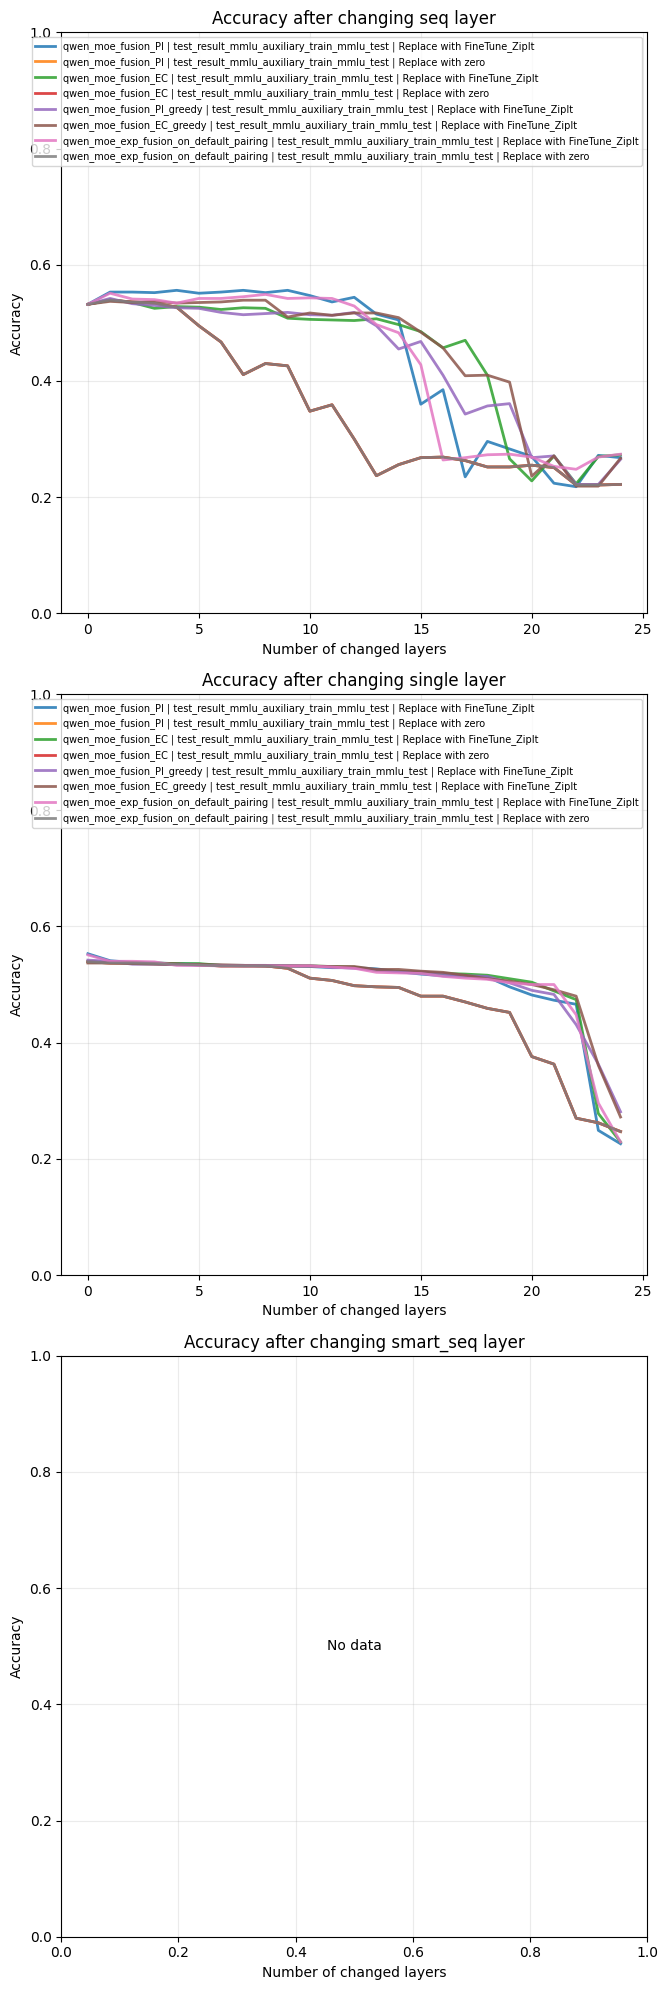

In [12]:
draw_many_data(many_data, save=True, figsize=(7, 20))

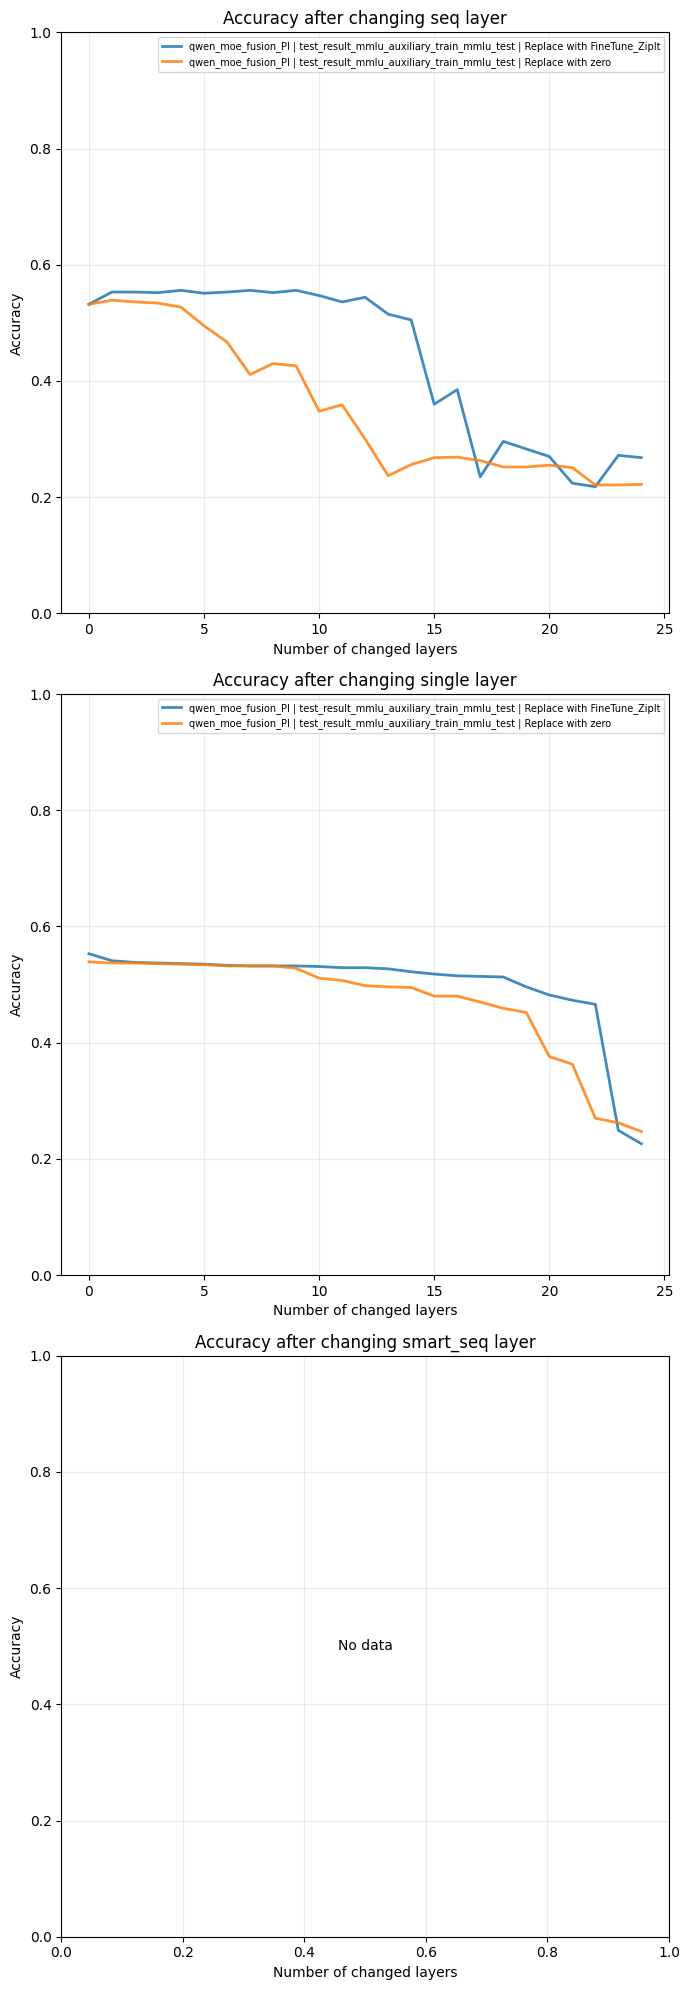

In [13]:
EXPERIMENT_DIRS = [

    '/glazkov-dev/qwen_moe_fusion_PI', #совпадает с greedy EC Почему-то

]
many_data = load_many_data(EXPERIMENT_DIRS)
draw_many_data(many_data, save=True, figsize=(7, 20))

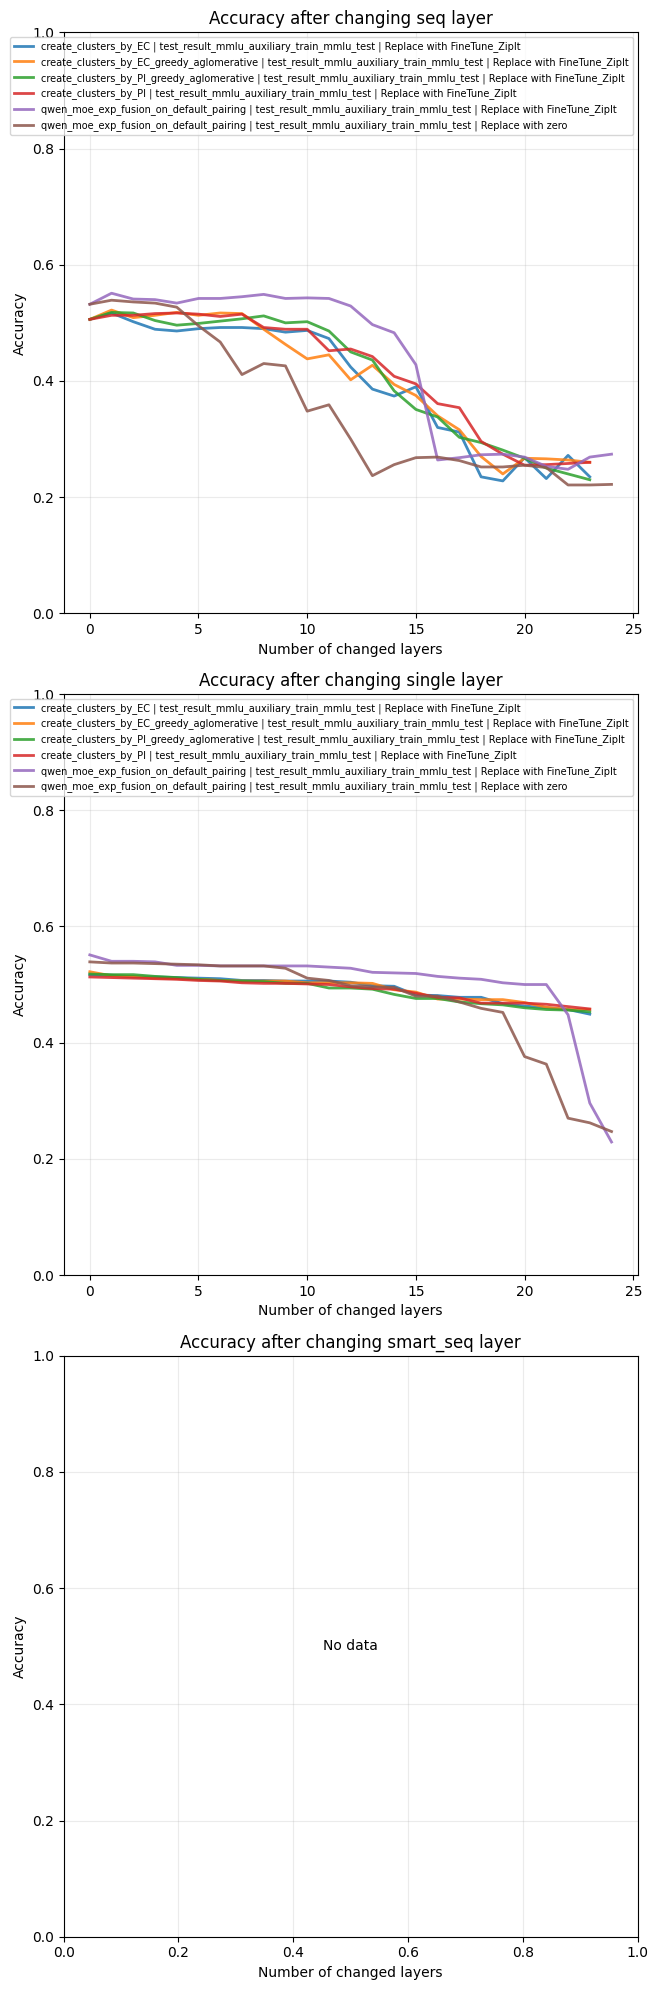

In [15]:
EXPERIMENT_DIRS_DEEPSEEK = [
    
    '/glazkov-dev/deepseek-ai/DeepSeek-V2-Lite-Chat/results/create_clusters_by_EC',
    '/glazkov-dev/deepseek-ai/DeepSeek-V2-Lite-Chat/results/create_clusters_by_EC_greedy_aglomerative',
    '/glazkov-dev/deepseek-ai/DeepSeek-V2-Lite-Chat/results/create_clusters_by_PI_greedy_aglomerative',
    '/glazkov-dev/deepseek-ai/DeepSeek-V2-Lite-Chat/results/create_clusters_by_PI',
    '/glazkov-dev/qwen_moe_exp_fusion_on_default_pairing'
]
many_data_deepseek = load_many_data(EXPERIMENT_DIRS_DEEPSEEK)
draw_many_data(many_data_deepseek, save=True, figsize=(7, 20))

In [ ]:
many_data = load_many_data(EXPERIMENT_DIRS)